**Regression on the Energy Efficiency Dataset**

**Course:** Intro to Data Science (IT803A)
**Student:** Mohammad Khizar Imran

**Goal:** predict a building's **Heating Load** and **Cooling Load** (kWh/m²) from 8 design features,

**Tasks:** Compare classical regression models with a neural network, track experiments with MLflow, and deploy the model.

Dataset: [UCI Energy Efficiency](https://archive.ics.uci.edu/dataset/242/energy+efficiency)

## Part 1 - Data Preparation & EDA

We need to import the important libraries which will be used throughout the notebook. Matplotlib is used for drawing the canvas and the labels whereas seaborn (built on matplotlib) is used to draw a polished version of the graphs/plots.

We will be importing the dataset first we have in the csv format and then we identify:
- Target features - the ones for which the predictions will be made.
- Features - the ones through which we will predict the targets.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

sns.set_theme(style="whitegrid", context="notebook")
HEAT, COOL, BLUE = "#eb6834", "#2a78d6", "#2a78d6"   # heating = orange, cooling = blue

df = pd.read_csv("data/energy_efficiency_data.csv")
TARGETS  = ["Heating_Load", "Cooling_Load"]
FEATURES = [c for c in df.columns if c not in TARGETS]
df.head()

,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


Now, when we do EDA (Exploratory Data Analysis) we check **3** things:
1. Is the data clean?
2. What does the data looks like?
3. How does the input features affect the target features.

In order to answer these **3** questions, we perform **7 steps**:
1. Structure and Statistics Summary - What's inside the table?
2. Missing & Duplicate values
3. Distributions - Normal or Skewed?
4. Outliers (if any)
5. Relationship between the features and target - to know which feature affects the target the most and make sure to feed that feature values in to the model.
6. Multicolinearity - do some features repeat each others information?
7. Decisions - What features to feed the model.

### 1. Structure and Statistics summary

In [2]:
print("Shape:", df.shape)
df.info()

Shape: (768, 10)
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Relative_Compactness       768 non-null    float64
 1   Surface_Area               768 non-null    float64
 2   Wall_Area                  768 non-null    float64
 3   Roof_Area                  768 non-null    float64
 4   Overall_Height             768 non-null    float64
 5   Orientation                768 non-null    int64  
 6   Glazing_Area               768 non-null    float64
 7   Glazing_Area_Distribution  768 non-null    int64  
 8   Heating_Load               768 non-null    float64
 9   Cooling_Load               768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


We used **two methods** of pandas to get some information about our data:
1. ```.shape``` - tells us about the number of rows and cols present in our dataset (rows,cols)
2. ```.info``` - tells us if there are any missing values present in the cols and the data type of cols.

In [14]:
pd.concat([df.describe().T.round(2), df.nunique().rename("n_unique")], axis=1)

,count,mean,std,min,25%,50%,75%,max,n_unique
Relative_Compactness,768.0,0.76,0.11,0.62,0.68,0.75,0.83,0.98,12
Surface_Area,768.0,671.71,88.09,514.50,606.38,673.75,741.12,808.50,12
Wall_Area,768.0,318.50,43.63,245.00,294.00,318.50,343.00,416.50,7
Roof_Area,768.0,176.60,45.17,110.25,140.88,183.75,220.50,220.50,4
Overall_Height,768.0,5.25,1.75,3.50,3.50,5.25,7.00,7.00,2
Orientation,768.0,3.50,1.12,2.00,2.75,3.50,4.25,5.00,4
Glazing_Area,768.0,0.23,0.13,0.00,0.10,0.25,0.40,0.40,4
Glazing_Area_Distribution,768.0,2.81,1.55,0.00,1.75,3.00,4.00,5.00,6
Heating_Load,768.0,22.31,10.09,6.01,12.99,18.95,31.67,43.10,586
Cooling_Load,768.0,24.59,9.51,10.90,15.62,22.08,33.13,48.03,636


The ```.info``` and ```.shape``` methods tells us about the table i.e. the outside picture but we need some more information regarding the actual values inside the table so for that we use the ```.describe``` and ```.nunique``` methods.

Now, the ```.describe``` method tells us **3** things in particular:
1. Shows us the variation in the values eg. Surface Area values are in hundreds and Glazing area values are below 1. If we feed models these values, model will consider the feature with high values as important feature and this would affect the results of the model. Now, that we know this fact, we know that we would need to do **Scaling** to normalize the data.
2. Shows us that there is no negative values or any placeholders values.
3. Shows us which features are really values and which are categories hidden behind values eg. **Overall_Height** has only 2 values and **Orientation** has only 4 values, which means these can be considered as categories.

Similarly, the ```.nunique``` method tells us **1** important thing - **Problem Type**. For instance here in the above table, the nunique value of **Heating Load** is **586** and it's minimum value is **6** and maximum value is **43**, which means that it's a continuous number in the range of **6-43**. Since, this is a continuous number to predict, this is a **Regression** problem.

### 2. Missing and Duplicate values

In [8]:
print("Missing values per column:\n", df.isna().sum(), sep="")
print("\nFully duplicated rows:", df.duplicated().sum())

Missing values per column:
Relative_Compactness         0
Surface_Area                 0
Wall_Area                    0
Roof_Area                    0
Overall_Height               0
Orientation                  0
Glazing_Area                 0
Glazing_Area_Distribution    0
Heating_Load                 0
Cooling_Load                 0
dtype: int64

Fully duplicated rows: 0


Since ```.info``` method tells us about the missing values, so why we calculate the missing values again? It's a valid question and the answer to this is simple. 

In our dataset there were no missing values according to the ```.info``` method as it said **786 non null values** for each feature but let's assume any feature had 10 missing values, how would that be represented? In table, it would have only written **758 non null values**. For one feature it seems like **easy to remember** but for a larger and compelex dataset, it gets harder. So, ```.isna``` checks each col for any missing value and keeps a count of that cols' missing value and tells us the exact number of missing values in that col.

Similar is the case with ```.duplicated```, it checks for the rows which are 100% identical. In our dataset, the first four rows seems to be duplicates but there are NOT. All of their values are same except for the ***Orientation*** col and since that's different, it's not a duplicate.

### 3. Distributions

Since, the ```nunique``` method from **Step 1** told us that our target values are **continuous number** - different high value numbers, they are easily and cleanly represented by ***Histogram*** and discrete values for other features so ***Bar charts*** fits best for them.

Now, from the ***Histogram*** we would need to see if the data distribution of target features is normal or skewed, and if skewed then close to balanced or not. If it's not close to balance. we would need to **Transform** the target values.

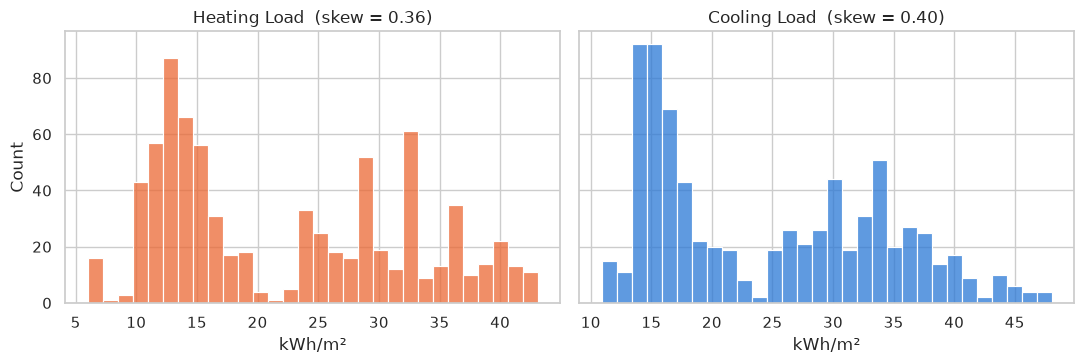

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, t, col in zip(axes, TARGETS, [HEAT, COOL]):
    sns.histplot(df[t], bins=30, color=col, ax=ax, edgecolor="white")
    ax.set_title(f"{t.replace('_', ' ')}  (skew = {df[t].skew():.2f})")
    ax.set_xlabel("kWh/m²")
plt.tight_layout(); plt.show()

From the ***Histogram*** we see that the distributions are **Right Skewed** but the skew value for the **Heating Load** is **0.36** and for **Cooling Load** it is **0.40** which means the data is roughly balanced and no need for the transformation.

What do we get from the ***Histograms***:
1. The data divides the buildings into two groups on both **Heating Load** and **Cooling Load**.

Now for each **Feature** we would need to know how often does each value appears and if there is any abnormality(any rare value) in the values.

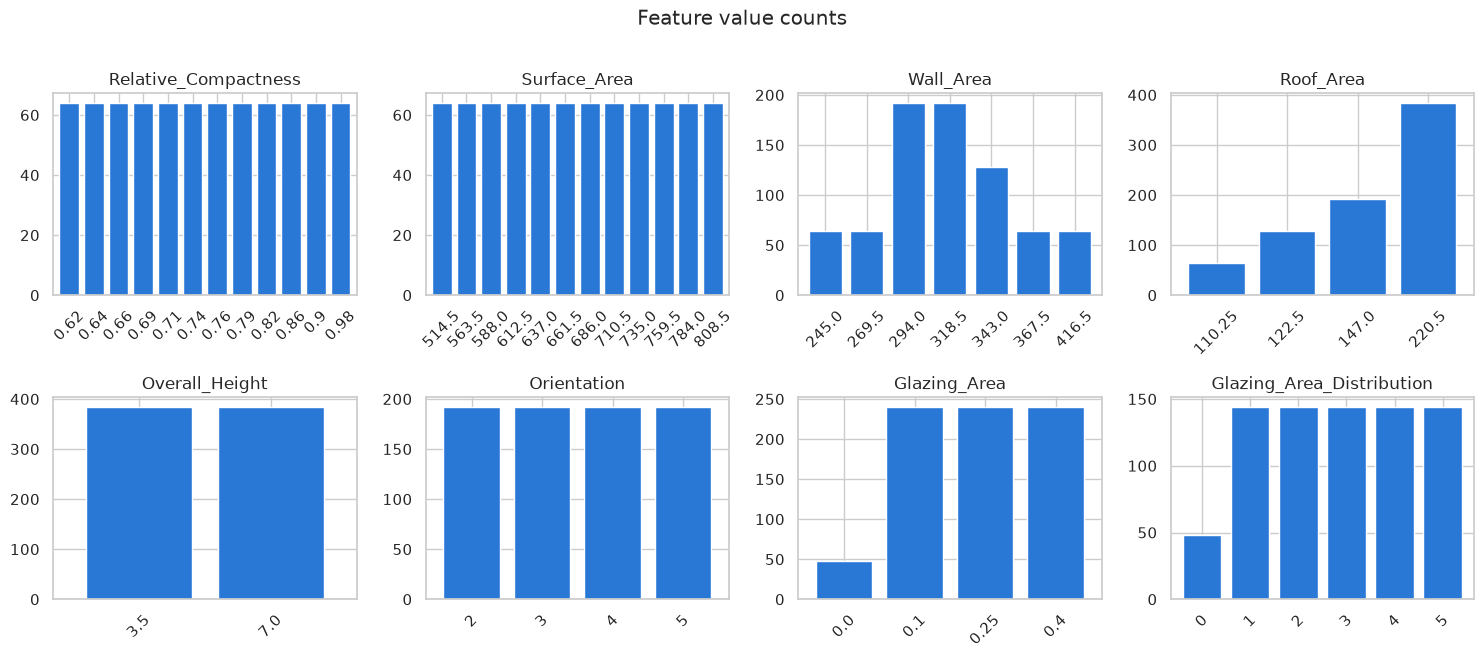

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, f in zip(axes.flat, FEATURES):
    df[f].value_counts().sort_index().plot.bar(ax=ax, color=BLUE, edgecolor="white", width=0.8)
    ax.set_title(f); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=45)
plt.suptitle("Feature value counts", y=1.01); plt.tight_layout(); plt.show()

The ***Bar Chart*** shows how often does each value appear and seeing from the bar charts, each value appear often equally eg. **384 builings** for both **3.5m** and **7m** height, **192 buildings** per orientation. This basically tells us that the data is balanced.

Although there is one exception for the ***Glazing_Area*** and the ***Glazing_Area_Distribution*** charts. **48 buildings** have **Glazing_Area=0** and the same **48 buildings** have **Glaze_Area_Distribution=0**, so that value simply repeats the fact that there are **no windows**.

### 4. Outliers

Now that we have the info of the dataset, no missing or duplicates and we know data distribution is balanced, we will be finding the plausible outliers.

To find the Outliers we will use **2 methods**:
1. The IQR (Inter Quartile Range) Method.
2. Identical Twin Check - uses the IQR method but with grouping the data

The IQR method basically have **5 Steps** but pandas does the most of us, we just need to input some formulas and the ranges (0.25, 0.75). 

1. **0.25** is the Lower Fence.
2. **0.75** is the Upper Fence.
3. We first find the medians **q1 and q2** of both lower and upper half.
4. Then calculate the IQR by **q3-q1**.
5. Then build fences i.e. allow **1.5 * IQR** for the extra room for each fence.
6. Then calculate the lower fence (**q1 - 1.5 * iqr**) and upper fence (**q3 + 1.5 * iqr**).

Then we see that every value should be withing the range of lower fence and upper fence. Anything outside that range is considered as **Outlier**.


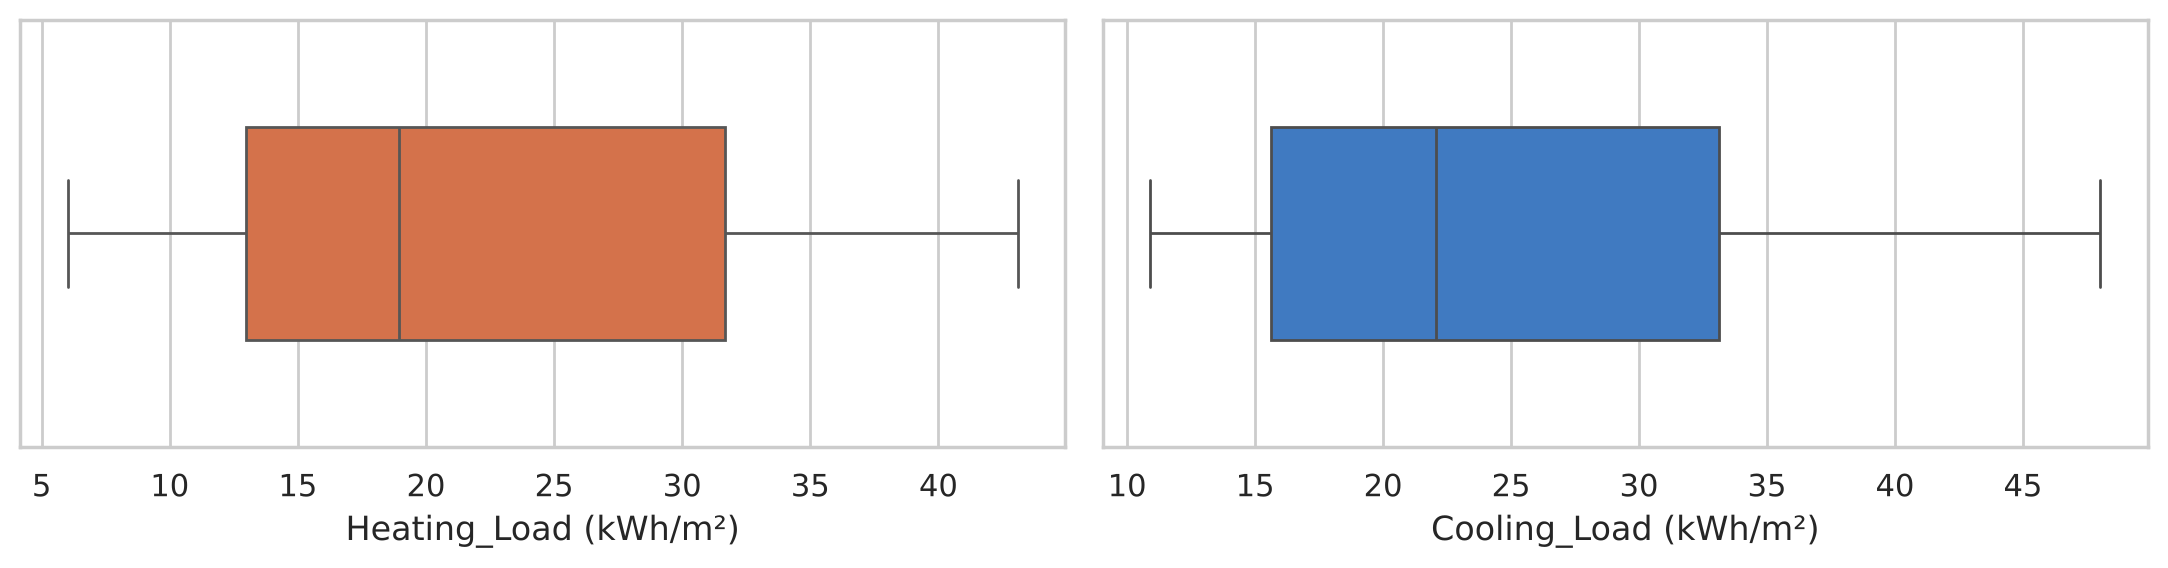

,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
IQR outliers,0,0,0,0,0,0,0,0,0,0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, t, col in zip(axes, TARGETS, [HEAT, COOL]):
    sns.boxplot(x=df[t], color=col, ax=ax, width=0.5); ax.set_xlabel(f"{t} (kWh/m²)")
plt.tight_layout(); plt.show()

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

df.apply(iqr_outliers).rename("IQR outliers").to_frame().T

In our plot there are no dots. The whiskers simply end at the smallest and largest buildings. That’s the **IQR result**. This means that there are no outliers but for surety we would do the **Identical Twin Check**.

So the **IQR Method** tells us that there are no outliers and the values looks normal but the **Identical Twin Check Method** tells us that no matter if the values look good overall, they still can be **odd values**. 

in this dataset, every design (same shape, same windows) was simulated 4 times, once facing each direction ***(North, East, South, West)***. Turning a building around barely changes its heating, so those 4 twins should have almost the same heating load.

Now, we will be checking this and to do this we have **4 Steps**:

1. Group the twins: buildings that are identical except for orientation.
2. Find each group’s middle value (median).
3. Measure how far each building is from its group’s median.
4. Sort by that distance: the top of the list is the most suspicious.

In [8]:
design_cols = [c for c in FEATURES if c != "Orientation"]
dev = df[["Heating_Load"]].copy()
dev["group_median"] = df.groupby(design_cols)["Heating_Load"].transform("median")
dev["abs_deviation"] = (df["Heating_Load"] - dev["group_median"]).abs()
pd.concat([df[design_cols + ["Orientation"]], dev], axis=1).sort_values("abs_deviation", ascending=False).head(5).round(2)

,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Glazing_Area,Glazing_Area_Distribution,Orientation,Heating_Load,group_median,abs_deviation
271,0.71,710.5,269.5,220.5,3.5,0.1,5,5,13.69,10.74,2.95
572,0.62,808.5,367.5,220.5,3.5,0.4,1,2,15.09,17.14,2.05
259,0.79,637.0,343.0,147.0,7.0,0.1,5,5,35.48,36.74,1.26
11,0.86,588.0,294.0,147.0,7.0,0.0,0,5,18.31,19.42,1.11
7,0.90,563.5,318.5,122.5,7.0,0.0,0,5,19.68,20.78,1.09


Now, if we look at the table, we need to look at **2 cols** specifically:
1. ```Heating_Load```
2. ```group_median```

For the **last 3** groups, there is not much difference between their heating load and group median values but for the **first 2** groups, the ```abs_deviation``` is big, which means that these two buildings can be considered as outliers.

Since, the gap in these values is minimal, and such small gap won't affect the model so we can **keep them**. 

### 5. Relationships between features and targets

So far in each step we have looked into each feature on it's own. Now, we need to see how each feature affect the ```energy_loads```.

We do this in **3 steps**:
1. The Correlation heatmap - numerically we see how each feature affects the energy load. **+1** means both go up together, **−1** means one goes up while the other goes down, **0** means no link.
2. Check whether a number is lying or not?
3. See what each relationship looks like.

First, we will be making the **Correlation Heatmap** and then analyzing it to see what features affect the energy load the most and the least.

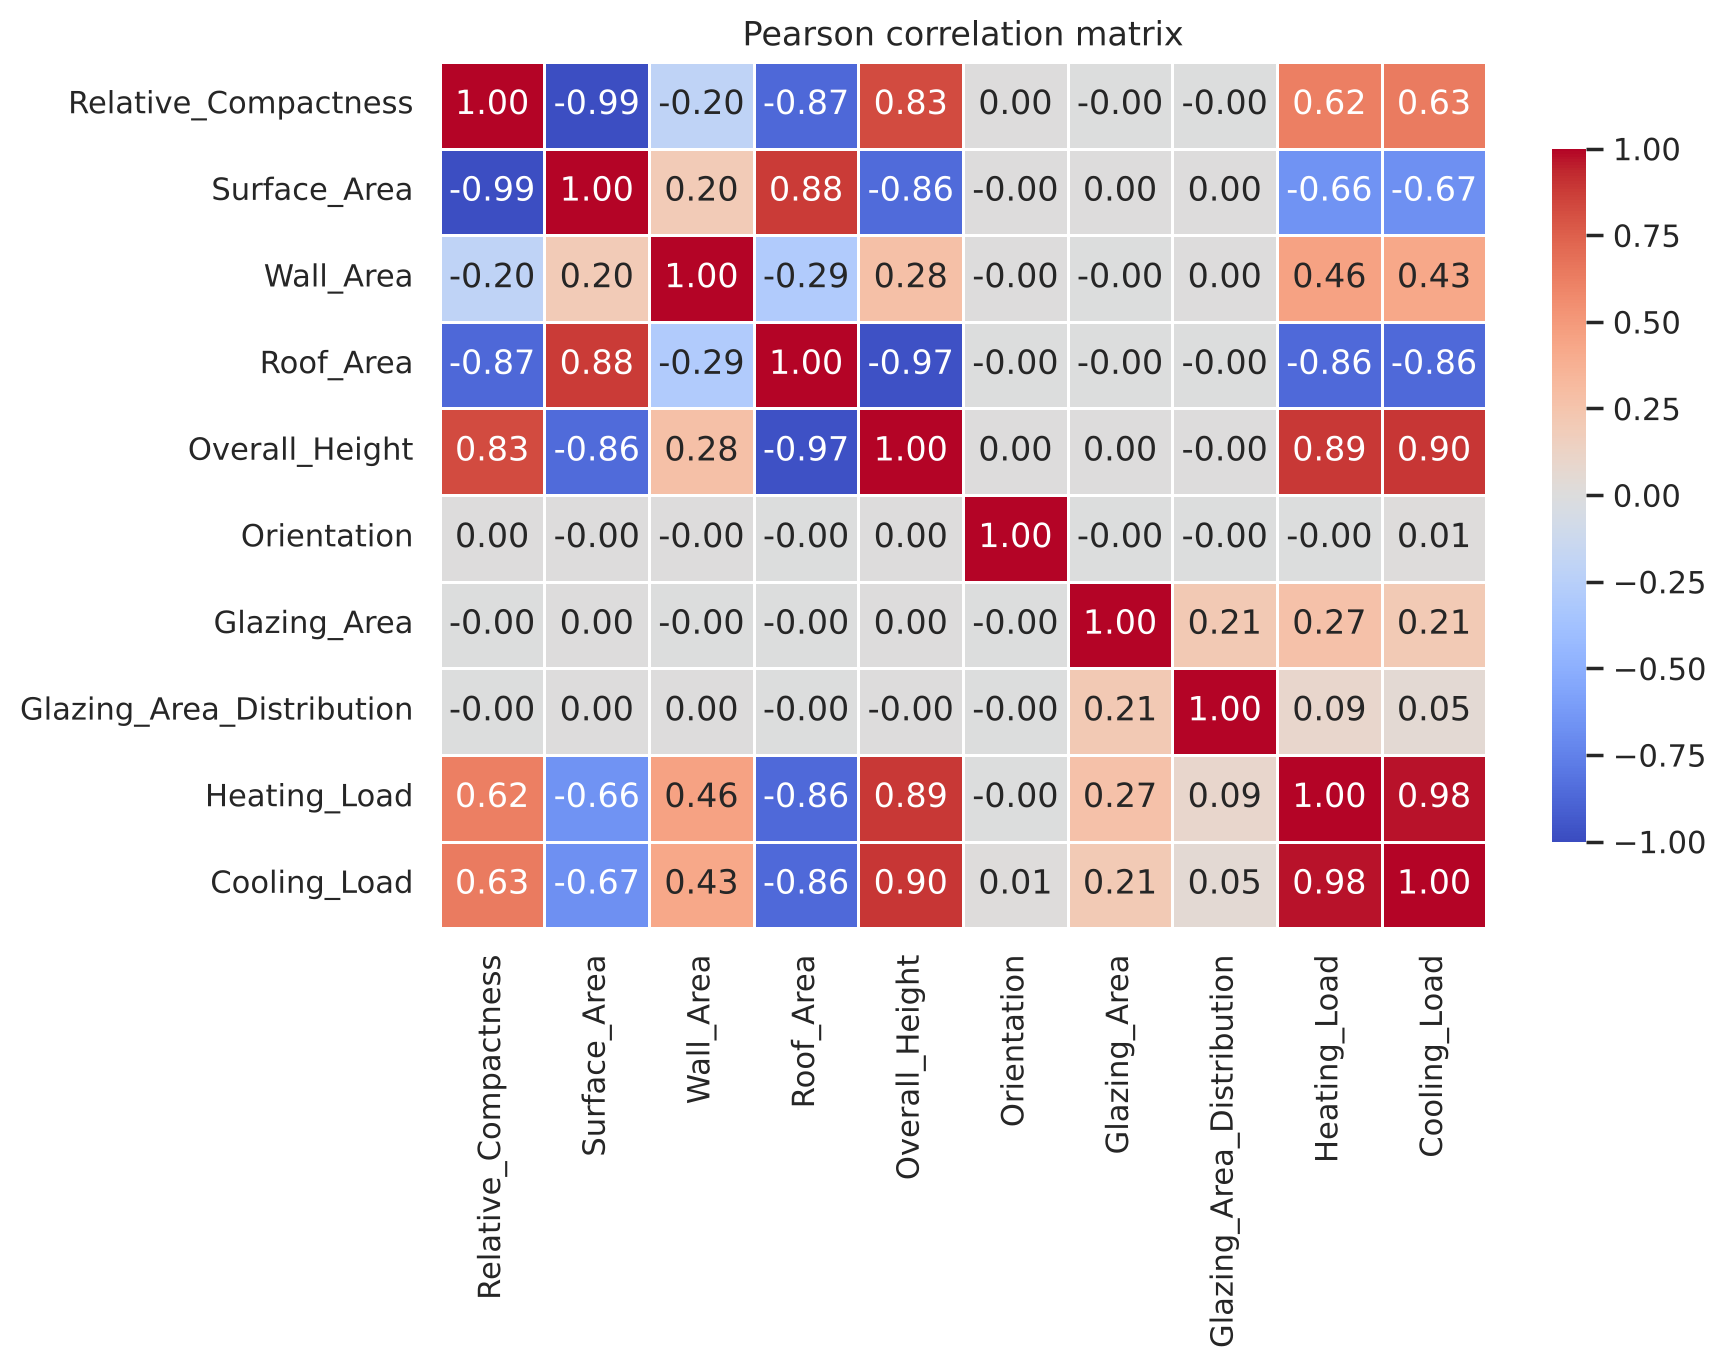

In [9]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Pearson correlation matrix"); plt.tight_layout(); plt.show()

Correlation summarises each relationship in one number and can **hide** its shape. Since every feature takes only a few values, we plot the average heating and cooling load at each feature value (with 95% confidence intervals) to see whether each effect is a straight trend, a jump, or flat.

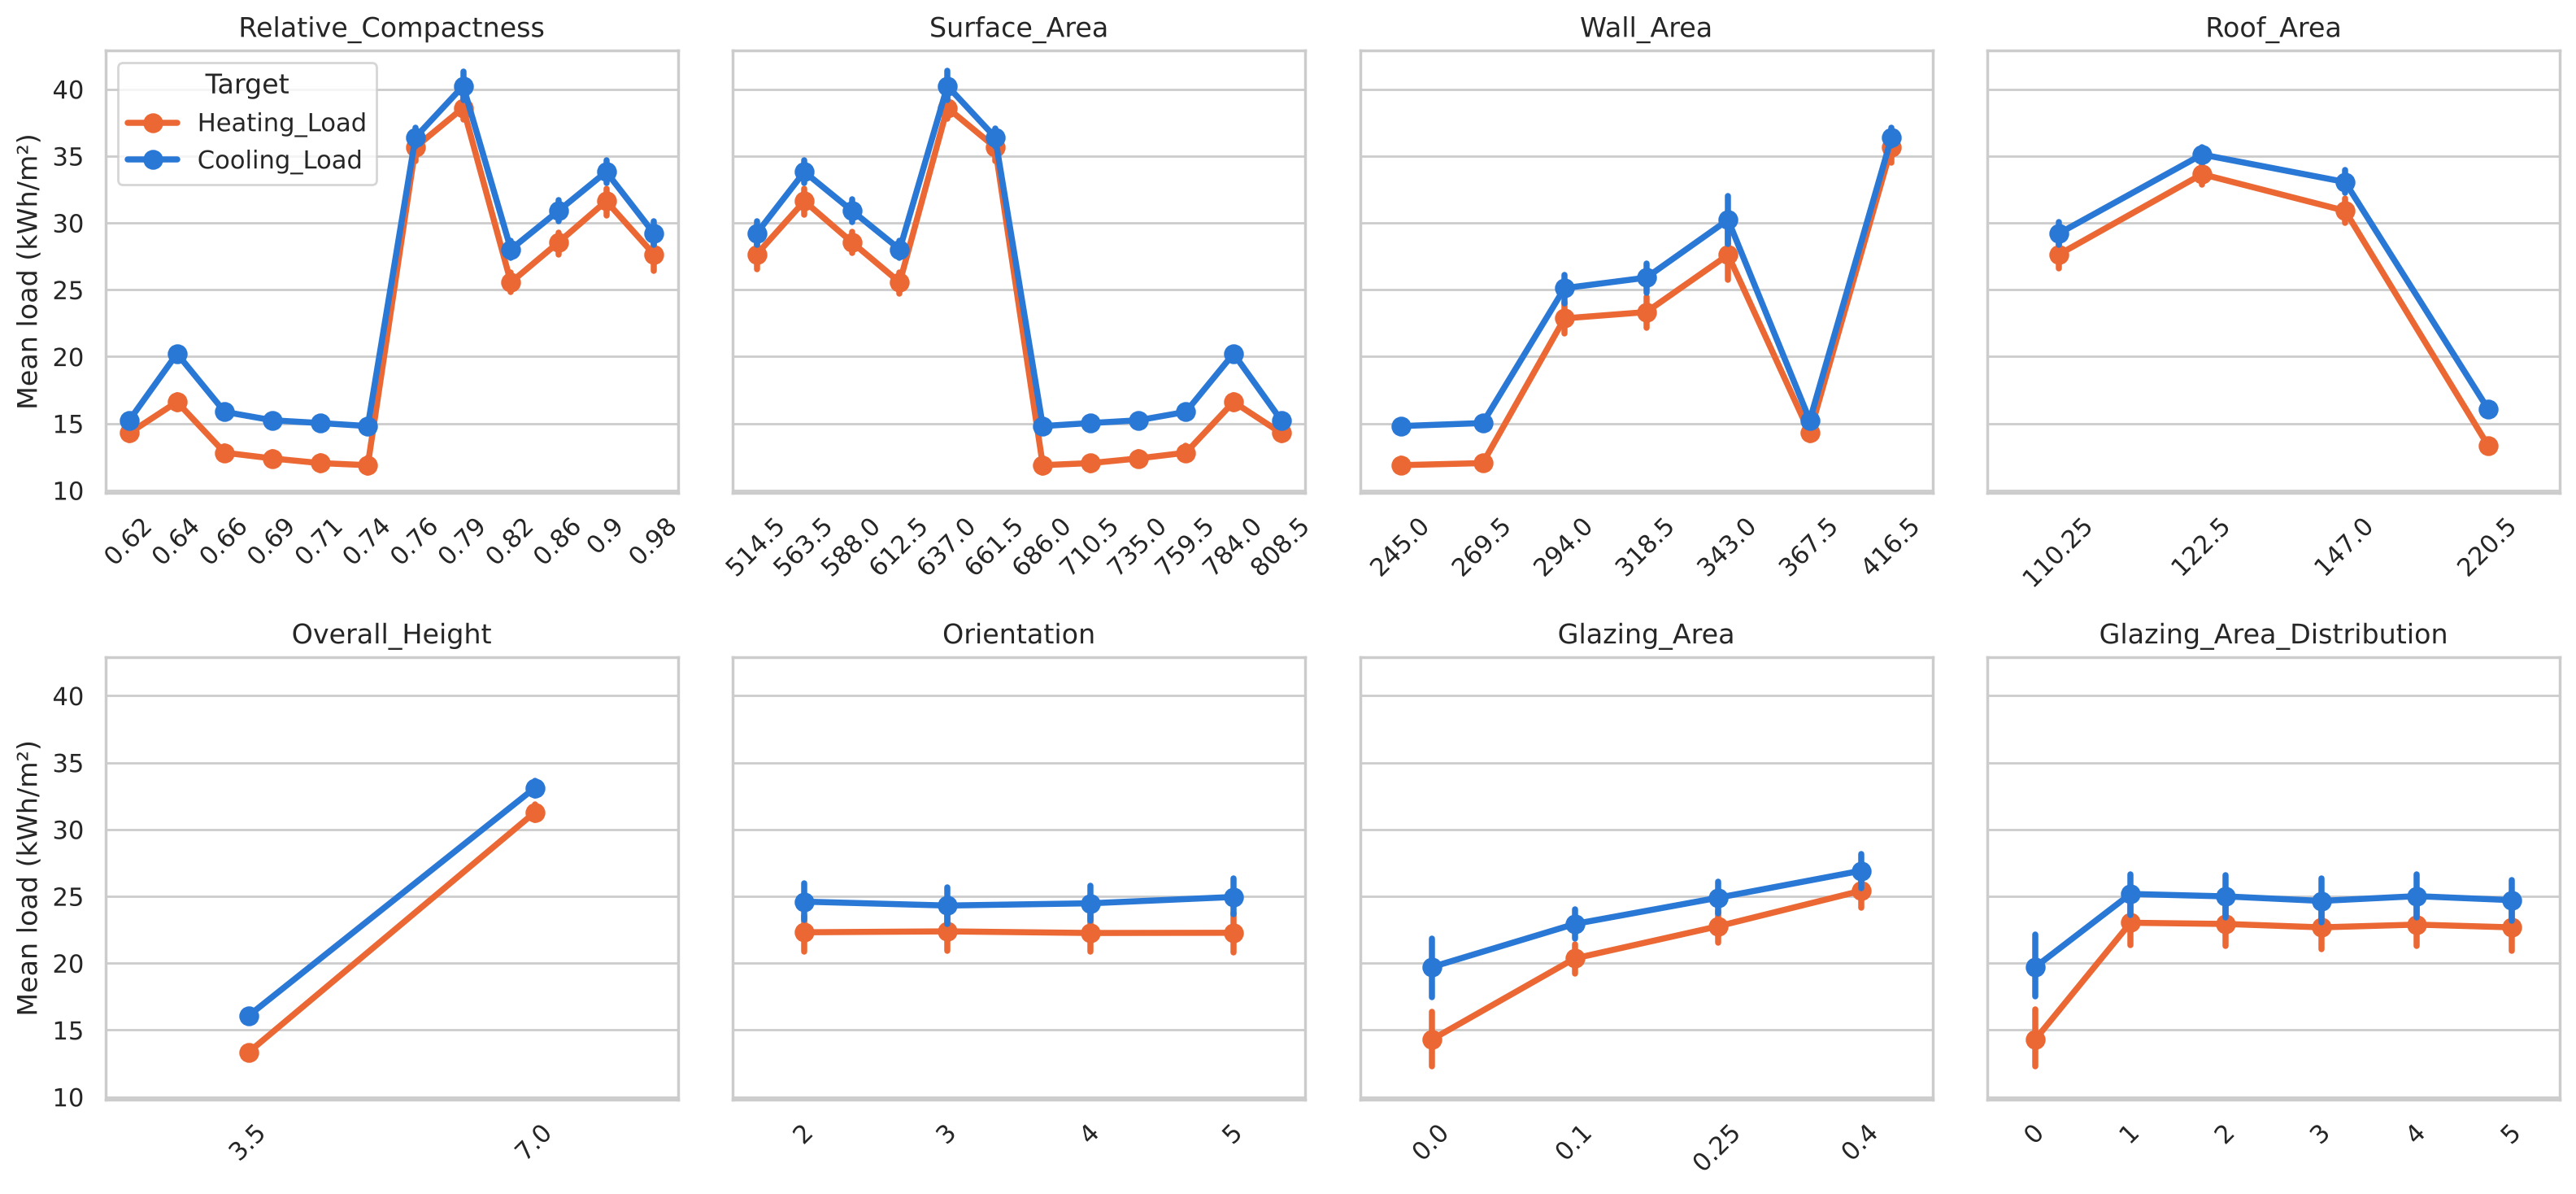

In [10]:
long = df.melt(id_vars=FEATURES, value_vars=TARGETS, var_name="Target", value_name="Load")
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5), sharey=True)
for ax, f in zip(axes.flat, FEATURES):
    sns.pointplot(data=long, x=f, y="Load", hue="Target", palette=[HEAT, COOL],
                  errorbar=("ci", 95), markers="o", linestyles="-", ax=ax, legend=(f == FEATURES[0]))
    ax.set_title(f); ax.set_xlabel(""); ax.set_ylabel("Mean load (kWh/m²)"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

Height has the largest effect: 7 m buildings need more than twice the energy of 3.5 m buildings. Higher glazing area raises the energy load gradually. Orientation shows no effect on average, and glazing distribution only matters as “no windows vs windows”. Several relationships are jumps or zig-zags rather than straight lines, telling us that a **non-linear model** would be a good fit.

```Relative_Compactness``` correlates positively with heating load **(+0.62)**, although physics says *a more compact building should lose less heat* - high relative compactness then low heating load. We split the buildings by height to check whether height is hiding behind this result.

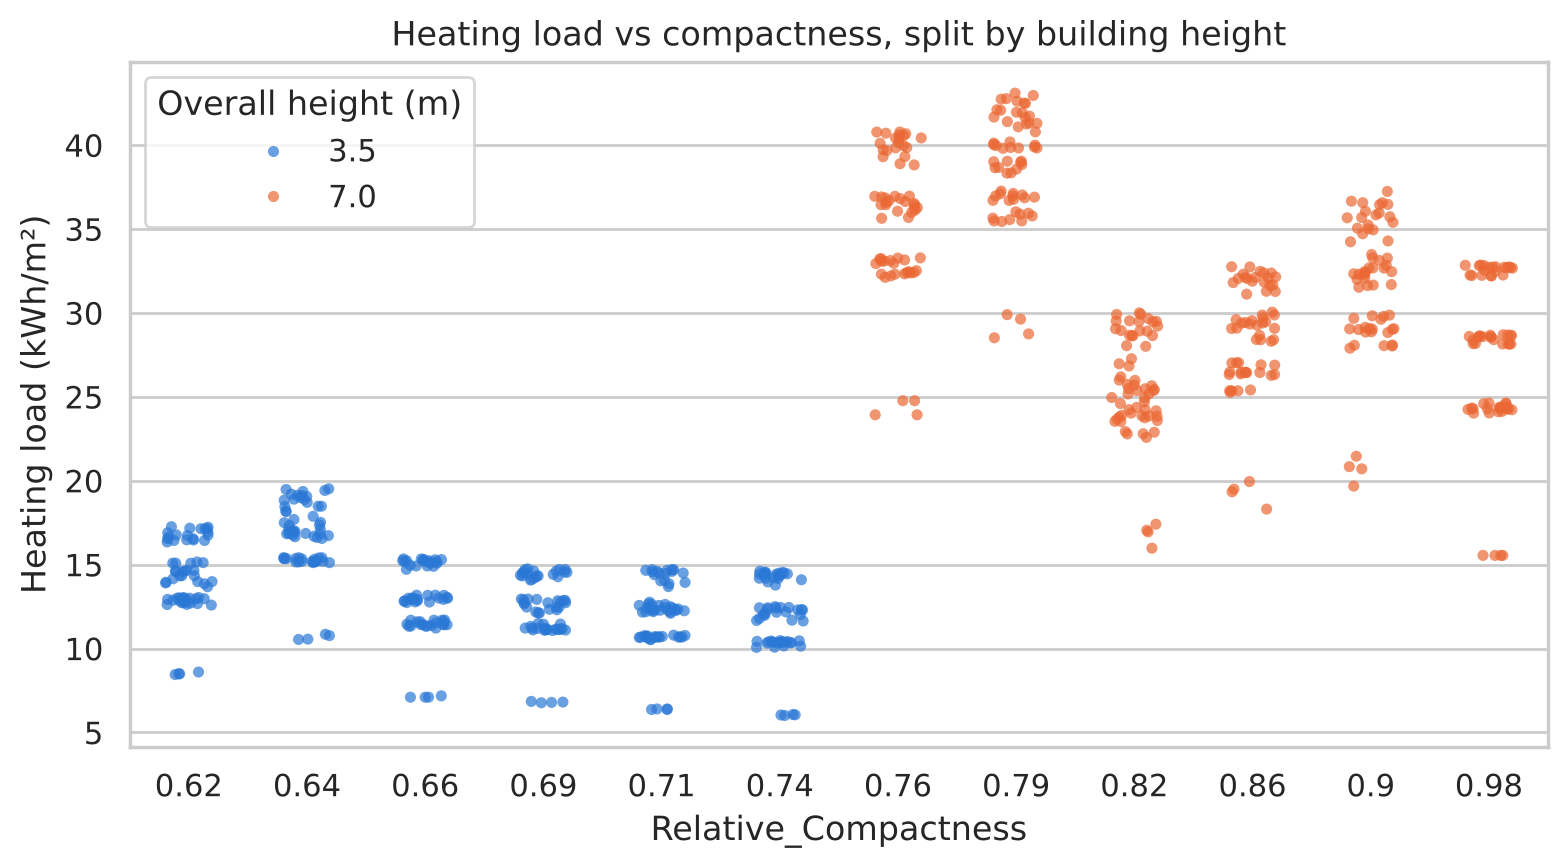

Correlation (Relative_Compactness vs Heating_Load)
  overall       : 0.62
  height = 3.5 m : -0.48
  height = 7.0 m : -0.44


In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.stripplot(data=df, x="Relative_Compactness", y="Heating_Load", hue="Overall_Height",
              palette=[BLUE, HEAT], jitter=0.2, size=4, alpha=0.7, ax=ax)
ax.set_ylabel("Heating load (kWh/m²)"); ax.legend(title="Overall height (m)")
ax.set_title("Heating load vs compactness, split by building height")
plt.tight_layout(); plt.show()

print("Correlation (Relative_Compactness vs Heating_Load)")
print("  overall       :", round(df["Relative_Compactness"].corr(df["Heating_Load"]), 2))
for h, d in df.groupby("Overall_Height"):
    print(f"  height = {h} m :", round(d["Relative_Compactness"].corr(d["Heating_Load"]), 2))

From the strip plot above, all **compact shapes (0.76–0.98)** are **7 m tall**, and all **less compact shapes (0.62–0.74)** are **3.5 m tall**. 

Comparing between the two groups, the tall, compact buildings use more energy because they are tall and this creates the *misleading positive correlation (+0.62)*. 

Comparing within each height group, more compact buildings need less heating **(−0.48 for 3.5 m, −0.44 for 7 m)**. 

This reversal is an example of **Simpson’s paradox**. Hence, **correlation** alone is therefore not used to judge or remove features.

Correlation said ```Orientation``` does nothing **(0.00)**. We need to see if that's really true?

We compare the **4 twin buildings** of each design (identical except for orientation) and calculate how much the load changes between them *(largest minus smallest)*. The results are averaged for each building shape.

In [12]:
design_cols = [c for c in FEATURES if c != "Orientation"]
orient_range = (df.groupby(design_cols)[TARGETS].agg(lambda s: s.max() - s.min())
                  .groupby("Relative_Compactness").mean().round(2))
orient_range.columns = ["Heating range from orientation", "Cooling range from orientation"]
orient_range

,Heating range from orientation,Cooling range from orientation
Relative_Compactness,,
0.62,0.39,0.45
0.64,0.27,0.39
0.66,0.17,0.43
0.69,0.23,0.61
0.71,0.37,0.66
0.74,0.21,0.51
0.76,0.83,0.95
0.79,1.48,8.86
0.82,1.23,3.77


Turning a building changes its heating load by less than 1.5 for every shape, so orientation barely affects heating. 

For cooling, the change is also small **(under 1)** for most shapes, but for **four tall shapes** *(compactness 0.79, 0.82, 0.86 and 0.90)* orientation alone changes the cooling load **above 1.5** *(8.86,3.77, 5.97, 4.90)*. 

These effects cancel out on average, which is why the correlation is 0. Orientation therefore affects cooling through an interaction with building shape, so it is kept as a feature.

### 1.6 Multicollinearity
**Variance Inflation Factor:** regress each feature on all the others; VIF = 1 / (1 − R²).
VIF > 10 means that feature is mostly explained by the others, so linear-model coefficients become unstable.

In [13]:
def vif_table(data, cols):
    out = {}
    for c in cols:
        others = [o for o in cols if o != c]
        r2 = LinearRegression().fit(data[others], data[c]).score(data[others], data[c])
        out[c] = np.inf if r2 >= 1 - 1e-12 else 1 / (1 - r2)
    return pd.Series(out, name="VIF").round(1)

print("Surface_Area == Wall_Area + 2 * Roof_Area for every row:",
      np.allclose(df["Surface_Area"], df["Wall_Area"] + 2 * df["Roof_Area"]))

pd.concat([vif_table(df, FEATURES).rename("VIF (all 8)"),
           vif_table(df, [f for f in FEATURES if f != "Surface_Area"]).rename("VIF (without Surface_Area)")], axis=1)

Surface_Area == Wall_Area + 2 * Roof_Area for every row: True


,VIF (all 8),VIF (without Surface_Area)
Relative_Compactness,105.5,105.5
Surface_Area,inf,NaN
Wall_Area,inf,27.7
Roof_Area,inf,211.9
Overall_Height,31.2,31.2
Orientation,1.0,1.0
Glazing_Area,1.0,1.0
Glazing_Area_Distribution,1.0,1.0


### 1.7 Feature selection & transformation
Decisions (justified by 1.3–1.6):
- **Drop `Surface_Area`**: it's an exact linear combination of `Wall_Area` and `Roof_Area` (infinite VIF), so it adds no information.
- **Keep `Roof_Area` and `Relative_Compactness` despite high VIF**: they are not *exact* duplicates, and Part 2 uses Ridge/Lasso, which are designed to handle correlated features.
- **Keep `Orientation`**: it has no average effect, but it changes cooling load by several kWh/m² for some shapes (an interaction a neural network can learn).
- **One-hot encode `Orientation` and `Glazing_Area_Distribution`**: they're category codes, not quantities.
- **No target transformation**: skew is about 0.4 and the two peaks come from building height, not from a long tail.
- **Scaling** (StandardScaler) is done *after* the train/test split in Part 2, fitting on the training set only, to avoid data leakage.

In [14]:
X = df.drop(columns=TARGETS + ["Surface_Area"])
X = pd.get_dummies(X, columns=["Orientation", "Glazing_Area_Distribution"], drop_first=True, dtype=int)
y = df[TARGETS]
print("X:", X.shape, "| y:", y.shape)
X.head()

X: (768, 13) | y: (768, 2)


,Relative_Compactness,Wall_Area,Roof_Area,Overall_Height,Glazing_Area,Orientation_3,Orientation_4,Orientation_5,Glazing_Area_Distribution_1,Glazing_Area_Distribution_2,Glazing_Area_Distribution_3,Glazing_Area_Distribution_4,Glazing_Area_Distribution_5
0,0.98,294.0,110.25,7.0,0.0,0,0,0,0,0,0,0,0
1,0.98,294.0,110.25,7.0,0.0,1,0,0,0,0,0,0,0
2,0.98,294.0,110.25,7.0,0.0,0,1,0,0,0,0,0,0
3,0.98,294.0,110.25,7.0,0.0,0,0,1,0,0,0,0,0
4,0.90,318.5,122.50,7.0,0.0,0,0,0,0,0,0,0,0
